# Will This Program Pay Off? Predicting Above-Median Earnings for College Programs
BUAN 6341 Applied Machine Learning, Group Project, Fall 2026

The notebook follows the five required sections: Motivation, Data, Model, Model Comparison, Conclusion.



## 1. Motivation

**Problem.** Every college program (one field of study at one school at one credential level) has a median
graduate salary four years after completion. The U.S. Department of Education also publishes the *national*
median for that same field and credential. We predict a yes/no outcome:

> **Will graduates of this program earn more than the national median for their field and degree?**

**Why it matters.** Students choose a *school* as much as a *major*. Two nursing bachelor's programs can lead to very
different salaries. We use only information available **before enrolling** (school selectivity, cost, size,
location, program size, typical debt, and labor-market data for the linked occupations) and deliberately leave out
every post-graduation outcome, so the model could actually be used by a prospective student.

**Reformulation.** Raw salary differs a lot by field (engineering vs. education), which would mostly teach the model
"which field pays more." Comparing each program to its own field's national median removes that effect and
creates a balanced binary target (~47% positive).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
                             log_loss, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
ROOT = Path('..')  # repo root: the CSV is at data/college_majors_2026.csv (python download_data.py)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
RES = Path('results'); RES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

## 2. Data

### 2.1 Data description
Source: `college_majors_2026.csv`, a program-level table that merges the **College Scorecard field-of-study file**
(earnings and debt by program), **IPEDS** institution data (control, admissions, SAT, tuition, enrollment),
and **BLS / O*NET** occupation data (employment, growth, wages, AI-tool usage) linked through the CIP-to-SOC crosswalk.

In [2]:
df = pd.read_csv(ROOT / 'data' / 'college_majors_2026.csv', low_memory=False)
print(df.shape)
df.head(3).T.head(30)

(227980, 72)


,0,1,2
program_id,opeid031505-51.07-1,opeid031505-51.35-1,opeid031505-52.04-1
unitid,NaN,NaN,NaN
opeid6,31505,31505,31505
institution_name,A - Technical College,A - Technical College,A - Technical College
institution_control,"Private, for-profit","Private, for-profit","Private, for-profit"
is_main_campus,1,1,1
institution_city,NaN,NaN,NaN
institution_state,NaN,NaN,NaN
institution_region,NaN,NaN,NaN
institution_latitude,NaN,NaN,NaN


In [3]:
miss = df.isna().mean().sort_values(ascending=False)
print('Share of programs with 4-year earnings reported:', df.median_earnings_4yr_usd.notna().mean().round(3))
miss.head(20).round(3)

Share of programs with 4-year earnings reported: 0.255


pct_working_in_state_5yr          0.829
count_working_in_state_5yr        0.829
earnings_trajectory_category      0.828
earnings_growth_pct_1yr_to_5yr    0.828
debt_to_earnings_1yr              0.810
payment_to_income_pct_1yr         0.810
debt_to_earnings_4yr              0.810
count_above_hs_threshold_5yr      0.808
pct_above_hs_threshold_5yr        0.808
median_monthly_payment_usd        0.795
median_debt_usd                   0.795
median_earnings_5yr_usd           0.778
pct_working_5yr                   0.778
earnings_cohort_size_5yr          0.778
median_earnings_1yr_usd           0.771
earnings_cohort_size_1yr          0.771
debt_borrower_count               0.745
earnings_vs_national_pct          0.745
earnings_cohort_size_4yr          0.745
median_earnings_4yr_usd           0.745
dtype: float64

Earnings are **privacy-suppressed** for ~75% of programs (cohorts too small to report). Those programs have no
outcome, so they cannot be used for supervised learning. We keep the 58,112 programs with a reported
4-year median, then remove duplicate rows for campuses that share one reported outcome (below).

In [4]:
d = df[df.median_earnings_4yr_usd.notna()].copy()
d['above_national'] = (d.earnings_vs_national_pct > 0).astype(int)
print(d.shape)

# Anomaly: multi-campus schools that report one shared outcome (outcomes_shared_across_campuses = 1) appear once
# per campus with identical earnings and debt. Keep one row per program, preferring the main campus.
KEY = ['opeid6', 'cip_code_4digit', 'credential_level']
dup = d.duplicated(subset=KEY, keep=False)
print('Rows in duplicated programs:', dup.sum(), '| all share outcomes:', d.loc[dup, 'outcomes_shared_across_campuses'].eq(1).all(),
      '| identical earnings within group:', d[dup].groupby(KEY).median_earnings_4yr_usd.nunique().eq(1).all())
d = d.sort_values('is_main_campus', ascending=False).drop_duplicates(subset=KEY).sort_index()
print('After de-duplication:', d.shape)
print(d.above_national.value_counts(normalize=True).round(3))

(58112, 73)
Rows in duplicated programs: 8637 | all share outcomes: True | identical earnings within group: True
After de-duplication: (51867, 73)
above_national
0    0.527
1    0.473
Name: proportion, dtype: float64


### 2.2 Exploratory data analysis

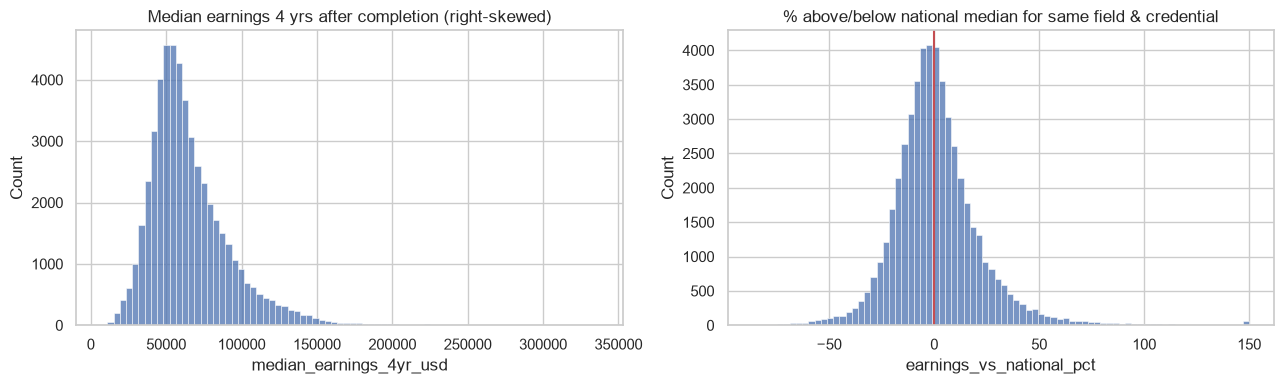

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(d.median_earnings_4yr_usd, bins=80, ax=ax[0]); ax[0].set_title('Median earnings 4 yrs after completion (right-skewed)')
sns.histplot(d.earnings_vs_national_pct.clip(-100, 150), bins=80, ax=ax[1]); ax[1].axvline(0, c='r')
ax[1].set_title('% above/below national median for same field & credential')
plt.tight_layout(); plt.savefig(FIG / 'eda_target.png', dpi=150); plt.show()

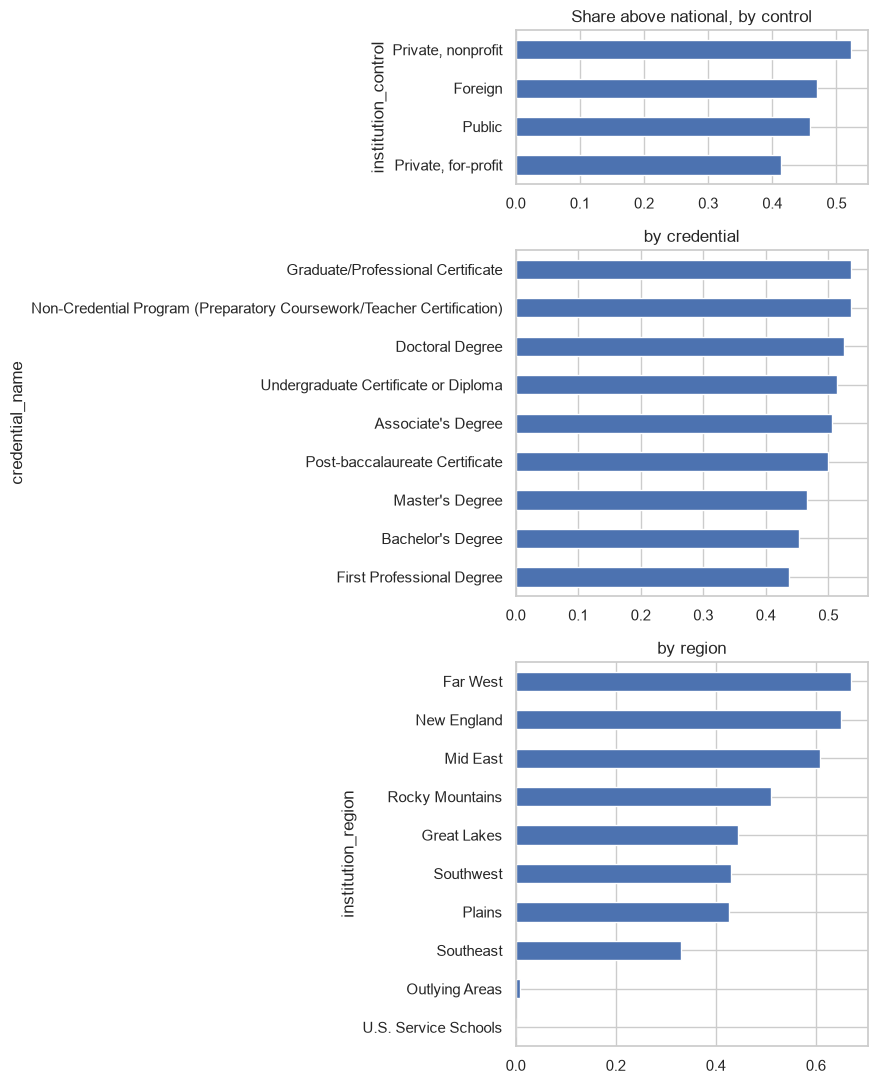

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(9, 11), gridspec_kw={'height_ratios': [4, 9, 10]})
d.groupby('institution_control').above_national.mean().sort_values().plot.barh(ax=ax[0], title='Share above national, by control')
d.groupby('credential_name').above_national.mean().sort_values().plot.barh(ax=ax[1], title='by credential')
d.groupby('institution_region').above_national.mean().sort_values().plot.barh(ax=ax[2], title='by region')
plt.tight_layout(); plt.savefig(FIG / 'eda_categories.png', dpi=150); plt.show()

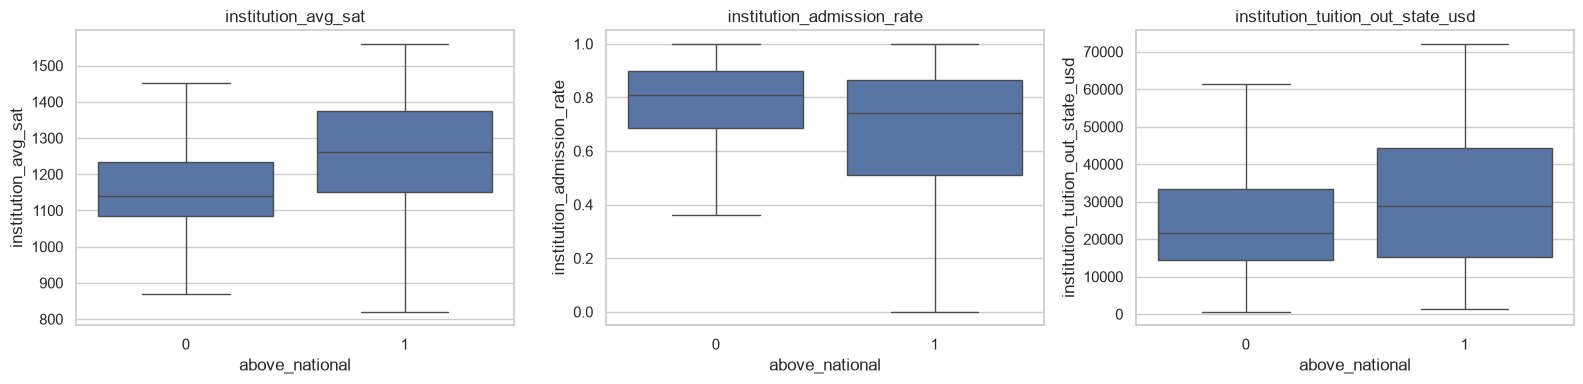

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['institution_avg_sat', 'institution_admission_rate', 'institution_tuition_out_state_usd']):
    sns.boxplot(data=d, x='above_national', y=c, ax=a, showfliers=False); a.set_title(c)
plt.tight_layout(); plt.savefig(FIG / 'eda_numeric.png', dpi=150); plt.show()

Selective, higher-SAT schools are far more likely to beat the national median; for-profit programs are least likely.
Note that SAT and admission rate are missing for ~35-50% of programs, mostly open-admission and two-year schools.
That missingness carries information in itself, so we add explicit missing-value indicators below.

### 2.3 Data preparation

**Leakage control.** We drop every column measured *after* graduation or computed from earnings:
1-yr/5-yr earnings, earnings growth and trajectory, debt-to-earnings, payment-to-income, employment rates,
the `earnings_vs_national_pct` column itself, and the status flags. We also drop identifiers and free text.

**Feature engineering.**
- Log-transform right-skewed counts and dollars (enrollment, awards, debt, occupation employment).
- `tuition_gap` = out-of-state minus in-state tuition (a proxy for public vs. private pricing).
- `awards_growth` = change in completions between the two award years (is the program growing?).
- Missing indicators for SAT, admission rate, debt, and tuition.
- Treat credential level and CIP family as categories (one-hot), not as numbers.

**Missing values.** Median imputation for numeric columns (inside the pipeline, fit on training folds only),
plus a separate "missing" category for categoricals.

**Duplicates and outliers.** Duplicate programs were removed above. For outliers, we follow the preprocessing module:
the extreme values here (very expensive schools, programs whose completions jumped from 0 to 50) are real data, not
data-entry mistakes, so we keep the rows. To stop them from dominating the linear model, we
**winsorize**: values are capped at the 1st and 99th percentiles. The caps are computed on the training set only,
after the split. Tree models are insensitive to this, but it helps logistic regression.

In [8]:
d['tuition_gap'] = d.institution_tuition_out_state_usd - d.institution_tuition_in_state_usd
d['awards_growth'] = (d.awards_year2 - d.awards_year1) / (d.awards_year1 + 1)
for c in ['institution_undergrad_enrollment', 'awards_year1', 'awards_year2', 'median_debt_usd',
          'debt_borrower_count', 'occupation_employment_2024_thousands', 'occupation_annual_openings_thousands']:
    d['log_' + c] = np.log1p(d[c])
for c in ['institution_avg_sat', 'institution_admission_rate', 'median_debt_usd', 'institution_tuition_in_state_usd']:
    d['miss_' + c] = d[c].isna().astype(int)

NUM = ['is_main_campus', 'institution_latitude', 'institution_longitude', 'institution_is_hbcu',
       'institution_admission_rate', 'institution_avg_sat', 'log_institution_undergrad_enrollment',
       'institution_tuition_in_state_usd', 'institution_tuition_out_state_usd', 'tuition_gap',
       'log_awards_year1', 'log_awards_year2', 'awards_growth', 'outcomes_shared_across_campuses',
       'national_median_earnings_4yr_usd', 'national_p25_earnings_4yr_usd', 'national_p75_earnings_4yr_usd',
       'log_median_debt_usd', 'log_debt_borrower_count', 'median_monthly_payment_usd',
       'linked_occupations_count', 'log_occupation_employment_2024_thousands', 'occupation_growth_pct_2024_34',
       'occupation_growth_pct_max', 'log_occupation_annual_openings_thousands', 'occupation_median_wage_2024_usd',
       'ai_software_occupation_share', 'expert_system_occupation_share', 'hot_technologies_mean_per_occupation'] + \
      [c for c in d.columns if c.startswith('miss_')]
CAT = ['institution_control', 'institution_region', 'institution_state', 'cip_family_title',
       'credential_name', 'distance_education', 'occupation_typical_entry_education']

X = d[NUM + CAT]; y = d.above_national; groups = d.opeid6
print(len(NUM), 'numeric +', len(CAT), 'categorical features')
print('Duplicate program rows:', d.duplicated(subset=['opeid6', 'cip_code_4digit', 'credential_level']).sum())

WINSOR = ['institution_tuition_in_state_usd', 'institution_tuition_out_state_usd', 'tuition_gap', 'awards_growth',
          'median_monthly_payment_usd', 'occupation_growth_pct_2024_34', 'occupation_growth_pct_max',
          'occupation_median_wage_2024_usd']
d[WINSOR].describe(percentiles=[.01, .5, .99]).T.round(2)

33 numeric + 7 categorical features
Duplicate program rows: 0


,count,mean,std,min,1%,50%,99%,max
institution_tuition_in_state_usd,46891.0,20000.77,18532.66,0.00,1356.00,11852.00,69314.00,72097.00
institution_tuition_out_state_usd,46891.0,27840.75,16839.30,600.00,4948.00,23500.00,69314.00,72097.00
tuition_gap,46891.0,7839.97,8874.64,0.00,0.00,5064.00,34200.00,43210.00
awards_growth,47665.0,0.07,1.54,-1.00,-0.75,-0.04,1.88,102.00
median_monthly_payment_usd,37920.0,304.27,320.19,14.00,58.00,240.00,1884.62,5227.00
occupation_growth_pct_2024_34,51062.0,4.96,4.23,-28.15,-3.74,4.67,16.18,21.07
occupation_growth_pct_max,51062.0,13.99,10.43,-25.90,0.00,11.20,40.10,49.90
occupation_median_wage_2024_usd,51062.0,88147.00,27675.65,37320.00,38035.00,82269.00,152129.00,229046.00


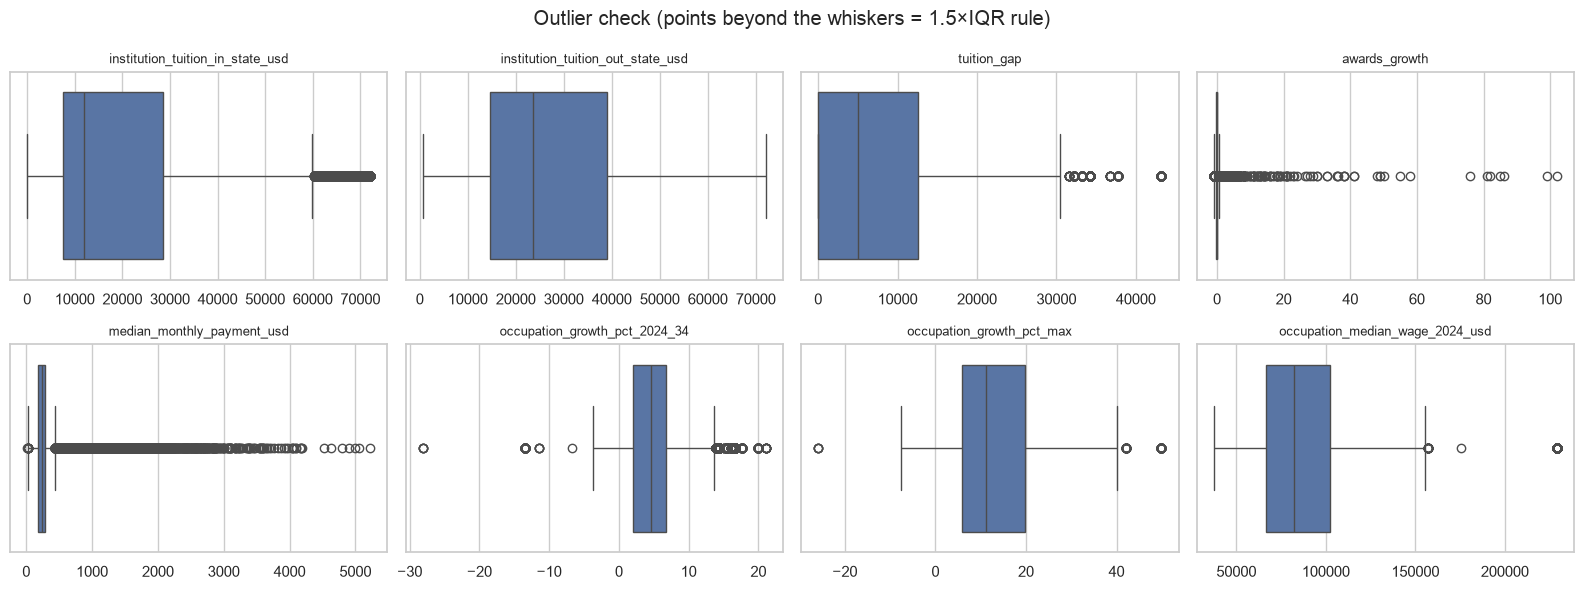

In [9]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for a, c in zip(ax.flat, WINSOR):
    sns.boxplot(x=d[c], ax=a); a.set_title(c, fontsize=9); a.set_xlabel('')
plt.suptitle('Outlier check (points beyond the whiskers = 1.5×IQR rule)'); plt.tight_layout()
plt.savefig(FIG / 'eda_outliers.png', dpi=150); plt.show()

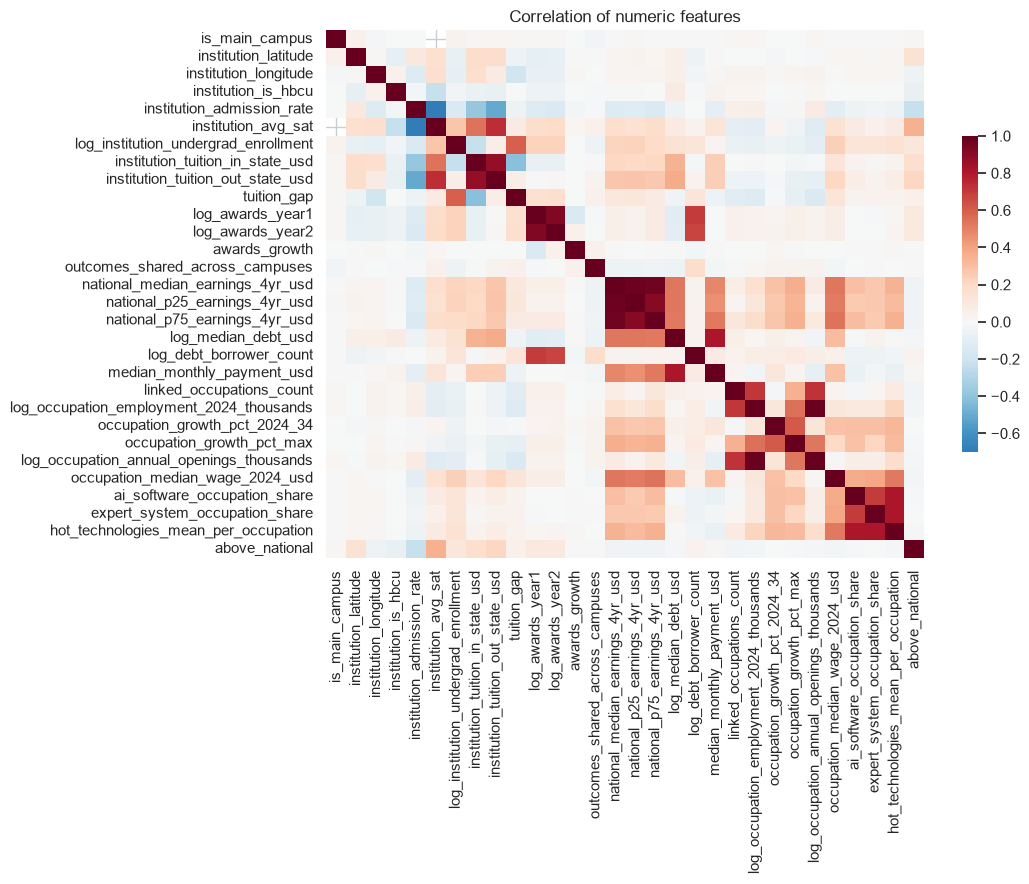

In [10]:
plt.figure(figsize=(11, 9))
sns.heatmap(d[NUM[:29] + ['above_national']].corr(), cmap='RdBu_r', center=0, cbar_kws={'shrink': .6})
plt.title('Correlation of numeric features'); plt.tight_layout(); plt.savefig(FIG / 'eda_corr.png', dpi=150); plt.show()

**Train/test split by institution.** A school usually has many programs. If programs from the same school appear in both
training and test sets, the model can memorize "this school pays well" and look better than it really is.
We use `GroupShuffleSplit` (80/20) grouped by `opeid6`, so every test program comes from a school the model has
**never seen**. Cross-validation for tuning uses `GroupKFold` the same way.

In [11]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups.iloc[tr]
print('train', X_tr.shape, 'test', X_te.shape, '| schools overlap:', len(set(g_tr) & set(groups.iloc[te])))
print('positive rate train/test:', y_tr.mean().round(3), y_te.mean().round(3))

# Winsorize: caps learned from the training set only, then applied to both sets
lo, hi = X_tr[WINSOR].quantile(.01), X_tr[WINSOR].quantile(.99)
X_tr, X_te = X_tr.copy(), X_te.copy()
X_tr[WINSOR] = X_tr[WINSOR].clip(lo, hi, axis=1); X_te[WINSOR] = X_te[WINSOR].clip(lo, hi, axis=1)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')),
                      ('oh', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False))]), CAT)])
cv = GroupKFold(n_splits=3)

train (40986, 40) test (10881, 40) | schools overlap: 0
positive rate train/test: 0.474 0.47


## 3. Model

We fit four supervised classifiers, all covered in lectures. Each is tuned with 3-fold **group** cross-validation on the training set
(the grid-search + K-fold CV workflow from Lecture 3), with ROC-AUC as the selection metric. The test set is used
only once, in Section 4. For the larger search spaces we use `RandomizedSearchCV`, a cheaper variant of grid search
that tries a random sample of the grid's combinations instead of all of them (Lecture 3, "Tuning is expensive").

| Model | Lecture | Hyperparameters searched |
|---|---|---|
| Logistic Regression (L1/L2) | L4 + L3 (regularization) | `C` (inverse regularization strength), penalty L1 (LASSO) vs L2 (Ridge) |
| Decision Tree (CART) | L7 | `max_depth`, `min_samples_leaf`, `ccp_alpha` (cost-complexity post-pruning) |
| Random Forest | L8 (bagging) | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| XGBoost | L8, L10a (gradient boosting / XGBoost) | `learning_rate`, `n_estimators`, `max_depth`, `min_child_weight`, `gamma`, `reg_lambda`, `subsample` |

In [12]:
def tune(name, model, grid, search='random', n_iter=12):
    pipe = Pipeline([('pre', pre), ('clf', model)])
    S = RandomizedSearchCV(pipe, grid, n_iter=n_iter, random_state=RANDOM_STATE) if search == 'random' \
        else GridSearchCV(pipe, grid)
    S.set_params(cv=cv, scoring='roc_auc', n_jobs=-1)
    S.fit(X_tr, y_tr, groups=g_tr)
    print(f'{name}: best CV AUC = {S.best_score_:.4f}  params = {S.best_params_}')
    return S

searches = {}

### 3.1 Logistic Regression
A linear model of the log-odds. Smaller `C` means stronger regularization. We apply the Ridge/LASSO idea from
Lecture 3 to classification: L1 (LASSO) can push coefficients to exactly zero (feature selection), while L2 (Ridge)
shrinks them. We grid-search both.

In [13]:
searches['Logistic Regression'] = tune('LogReg', LogisticRegression(solver='liblinear', max_iter=2000),
    {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l1', 'l2']}, search='grid')

LogReg: best CV AUC = 0.7459  params = {'clf__C': 0.1, 'clf__penalty': 'l2'}


### 3.2 Decision Tree (CART)
A single CART tree that splits on Gini impurity. An unpruned tree overfits, so we tune pre-pruning (`max_depth`,
`min_samples_leaf`) and cost-complexity post-pruning (`ccp_alpha`), as in Lecture 7. This is the building block of
the two ensembles below.

In [14]:
from sklearn.tree import DecisionTreeClassifier
searches['Decision Tree'] = tune('Tree', DecisionTreeClassifier(random_state=RANDOM_STATE),
    {'clf__max_depth': [6, 10, 15, None], 'clf__min_samples_leaf': [20, 50, 100],
     'clf__ccp_alpha': [0, 1e-4, 5e-4]}, search='grid')

Tree: best CV AUC = 0.7179  params = {'clf__ccp_alpha': 0.0001, 'clf__max_depth': None, 'clf__min_samples_leaf': 100}


### 3.3 Random Forest
Bagging plus random feature subsets (Lecture 8): an average of many decorrelated decision trees. Depth and leaf size
control overfitting, and `max_features` controls how decorrelated the trees are.

In [15]:
searches['Random Forest'] = tune('RF', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 15, 25], 'clf__min_samples_leaf': [1, 3, 10],
     'clf__max_features': ['sqrt', 0.3]}, n_iter=10)

RF: best CV AUC = 0.7838  params = {'clf__n_estimators': 200, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 25}


### 3.4 XGBoost
Gradient boosting trees (Lectures 8 and 10a) start from a constant prediction. Each round adds a small tree fit to the
negative gradient of the log-loss, scaled down by the learning rate ("shrinkage"). XGBoost adds two things covered in
Lecture 10a: (1) a cost function that penalizes tree complexity, through the leaf-count penalty `gamma` plus L2
regularization `reg_lambda`, and (2) histogram split-finding (`tree_method='hist'`, the "cut into L pieces / dices"
idea), which makes training fast.
**Tuned**, because the lecture warns that XGBoost is "sensitive to hyperparameters":
- `learning_rate` and `n_estimators` together set how far boosting goes. The lecture notes that more learners and
  bigger learner weights both raise the risk of overfitting.
- `max_depth` and `min_child_weight` limit tree size.
- `gamma` and `reg_lambda` are XGBoost's own overfitting penalties.
- `subsample` trains each tree on a random 80% of rows, which adds bagging-style variance reduction.

In [16]:
searches['XGBoost'] = tune('XGB', XGBClassifier(tree_method='hist', eval_metric='logloss', n_jobs=1,
                                                random_state=RANDOM_STATE),
    {'clf__learning_rate': [0.03, 0.06, 0.1], 'clf__n_estimators': [300, 600], 'clf__max_depth': [4, 6, 8],
     'clf__min_child_weight': [1, 5, 20], 'clf__gamma': [0, 1], 'clf__reg_lambda': [1, 5],
     'clf__subsample': [0.8, 1.0]}, n_iter=15)

XGB: best CV AUC = 0.7873  params = {'clf__subsample': 0.8, 'clf__reg_lambda': 5, 'clf__n_estimators': 600, 'clf__min_child_weight': 1, 'clf__max_depth': 6, 'clf__learning_rate': 0.03, 'clf__gamma': 0}


## 4. Model Comparison

**Metrics.** The classes are roughly balanced, so we report:
- **ROC-AUC**: ranking quality across all thresholds (our primary metric).
- **PR-AUC (average precision)** and the precision-recall curve: how precision trades off against recall as the cutoff moves.
- **Accuracy** and **F1**: performance at the default 0.5 threshold.
- **Precision / Recall**: precision matters to a student who wants to avoid a program flagged "high-paying" that isn't.
- **Log loss**: quality of the predicted probabilities.

In [17]:
rows, probs = [], {}
for name, S in searches.items():
    p = S.predict_proba(X_te)[:, 1]; yhat = (p >= .5).astype(int); probs[name] = p
    rows.append({'Model': name, 'CV AUC': S.best_score_, 'Test AUC': roc_auc_score(y_te, p),
                 'PR-AUC': average_precision_score(y_te, p),
                 'Accuracy': accuracy_score(y_te, yhat), 'Precision': precision_score(y_te, yhat),
                 'Recall': recall_score(y_te, yhat), 'F1': f1_score(y_te, yhat), 'Log loss': log_loss(y_te, p)})
results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('Test AUC', ascending=False)
results.to_csv(RES / 'model_comparison.csv')
print('Majority-class baseline accuracy:', round(max(y_te.mean(), 1 - y_te.mean()), 4))
results

Majority-class baseline accuracy: 0.5295


,CV AUC,Test AUC,PR-AUC,Accuracy,Precision,Recall,F1,Log loss
Model,,,,,,,,
XGBoost,0.7873,0.7813,0.7684,0.7027,0.6975,0.6499,0.6729,0.5564
Random Forest,0.7838,0.7783,0.7636,0.6999,0.6972,0.6404,0.6675,0.5648
Logistic Regression,0.7459,0.7350,0.7035,0.6730,0.6635,0.6189,0.6404,0.6012
Decision Tree,0.7179,0.6975,0.6598,0.6455,0.6266,0.6101,0.6182,0.6417


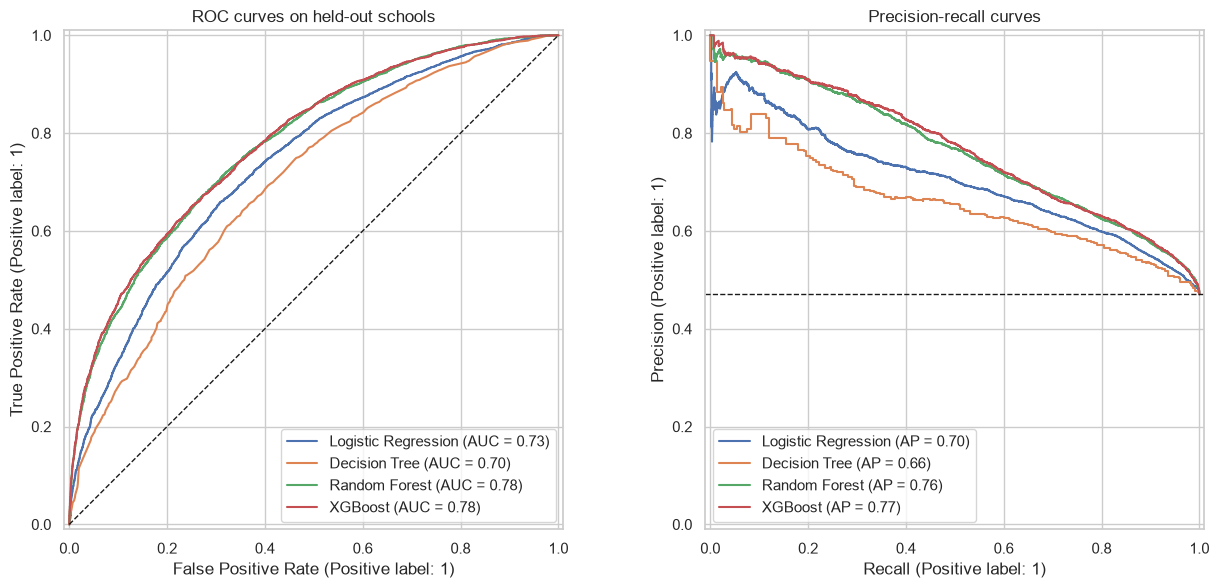

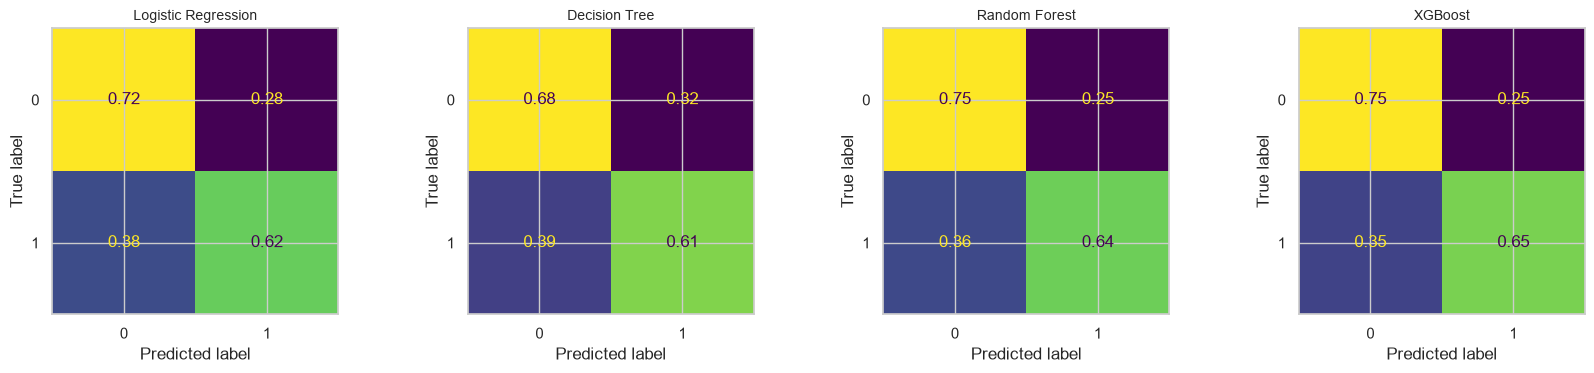

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_te, p, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_te, p, name=name, ax=ax[1])
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_title('ROC curves on held-out schools')
ax[1].axhline(y_te.mean(), c='k', ls='--', lw=1, label='No-skill'); ax[1].set_title('Precision-recall curves')
plt.tight_layout(); plt.savefig(FIG / 'roc_pr_curves.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, len(probs), figsize=(4.2 * len(probs), 3.8))
for a, (name, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, (p >= .5).astype(int), ax=a, colorbar=False, normalize='true',
                                            values_format='.2f'); a.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'confusion_matrices.png', dpi=150); plt.show()

### 4.1 What drives the best model? (permutation importance on the test set)

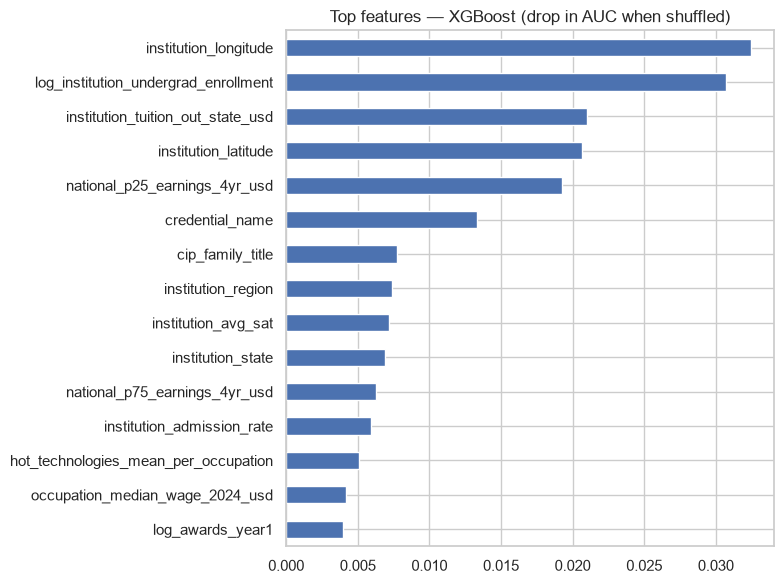

In [19]:
best_name = results.index[0]; best = searches[best_name].best_estimator_
sub = X_te.sample(min(4000, len(X_te)), random_state=RANDOM_STATE)
pi = permutation_importance(best, sub, y_te.loc[sub.index], scoring='roc_auc', n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=sub.columns).sort_values(ascending=False)
imp.to_csv(RES / 'permutation_importance.csv')
imp.head(15)[::-1].plot.barh(figsize=(8, 6), title=f'Top features — {best_name} (drop in AUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG / 'feature_importance.png', dpi=150); plt.show()

In [20]:
coef_pipe = searches['Logistic Regression'].best_estimator_
names = coef_pipe.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(coef_pipe.named_steps['clf'].coef_[0], index=names)
pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).round(3)

cat__institution_state_DC                                                         0.781
cat__institution_region_Far West                                                  0.741
cat__institution_control_Foreign                                                  0.717
cat__institution_state_HI                                                         0.622
cat__institution_region_Mid East                                                  0.607
cat__institution_state_RI                                                         0.591
cat__institution_state_UT                                                         0.567
cat__institution_state_VA                                                         0.562
cat__cip_family_title_Engineering/Engineering-Related Technologies/Technicians    0.496
num__national_median_earnings_4yr_usd                                             0.475
cat__institution_state_PR                                                        -1.043
cat__institution_region_Outlying

## 5. Conclusion
See `report/report.md` for the written conclusion. It is filled in from the results above.